<a href="https://colab.research.google.com/github/JulioRan09/Porgramacion-Predictiva/blob/main/PracticaRegresionLinealMultiple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maestría en Inteligencia Artificial y Analítica de Datos

## Programación para Analítica Descriptiva y Predictiva - Marzo 2025
## Práctica: Práctica: Regresión Lineal Múltiple
---


## Datos del Estudiante

*   Apellidos y Nombre: Rangel García Julio
*   Matrícula: 276572

---



##  Objetivo de aprendizaje
Al finalizar esta práctica, el estudiante será capaz de **aplicar regresión lineal múltiple utilizando Scikit-Learn para modelar la relación entre varias variables independientes y una variable dependiente**, verificar los supuestos del modelo, interpretar los coeficientes, analizar la correlación entre predictores y evaluar el rendimiento del modelo utilizando métricas como el MSE, RMSE y R².

Datos
Trabajarás con el archivo `advertising.csv`, que contiene información sobre el gasto publicitario en diferentes medios y las ventas obtenidas:

-`TV`: inversión en publicidad televisiva.

-`Radio`: inversión en publicidad en radio.

-`Newspaper`: inversión en publicidad en periódicos.

`Sales`: ventas del producto (variable dependiente).

## Parte 1: Carga de datos y bibliotecas
1. Importa las bibliotecas necesarias.
2. Carga el archivo `advertising.csv`.
3. Muestra las primeras filas del dataframe.
4. Describe estadísticamente las variables.

In [2]:
# Tu código aquí
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant


# 2. Cargar el dataset de advertising
df = pd.read_csv('/content/advertising.csv')

# 3. Mostrar las primeras filas del dataframe
print(df.head())

# 4. Describir estadísticamente las variables
print(df.describe())

      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3   12.0
3  151.5   41.3       58.5   16.5
4  180.8   10.8       58.4   17.9
               TV       Radio   Newspaper       Sales
count  200.000000  200.000000  200.000000  200.000000
mean   147.042500   23.264000   30.554000   15.130500
std     85.854236   14.846809   21.778621    5.283892
min      0.700000    0.000000    0.300000    1.600000
25%     74.375000    9.975000   12.750000   11.000000
50%    149.750000   22.900000   25.750000   16.000000
75%    218.825000   36.525000   45.100000   19.050000
max    296.400000   49.600000  114.000000   27.000000


## Parte 2: Análisis exploratorio de los datos
### 2.1  Análisis de la Relación Lineal entre la variable dependiente y las independientes
1. Grafica dispersión entre cada variable independiente (`TV`, `Radio`, `Newspaper`) y `Sales`. Usa también regplot.
2. Interpreta visualmente la relación entre variables.

In [3]:
#Antes de realizar el punto 1 verifiquemos algunas cosas
# Comprobamos si hay valores nulos
print("\nComprobando valores nulos:")
print(df.isnull().sum())


Comprobando valores nulos:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64


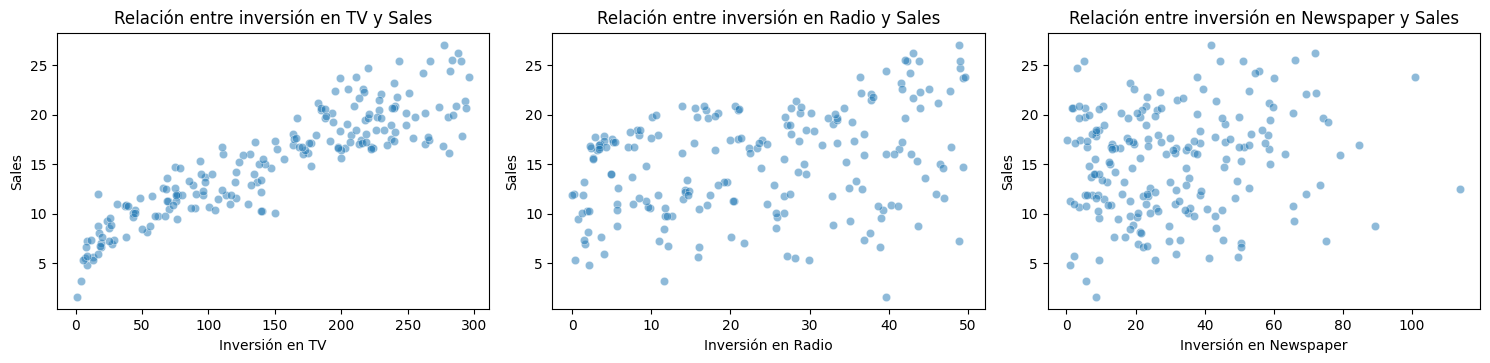

In [4]:
# Gráficos de dispersión
# 1. Grafiquemos cada vaiable independiente

# 4. Visualización de scatterplots entre todas las características y la variable objetivo 'PRICE'
plt.figure(figsize=(15, 10))
for i, column in enumerate(df.columns[:-1]):  # Excluimos la columna 'PRICE'
    plt.subplot(3, 3, i+1)
    sns.scatterplot(x=df[column], y=df['Sales'], alpha=0.5)
    plt.title(f"Relación entre inversión en {column} y Sales")
    plt.xlabel(f"Inversión en {column}")
    plt.ylabel("Sales")

plt.tight_layout()
plt.show()


## 2. Interpretación
Al graficar la dispersión de la inversión en cada medio, `TV`, `Radio` y `Newspaper`, contra las ventas del producto `sales` observamos una fuerte correlación positiva para la comparativa de TV, lo que nos da un primer indicio de que es el medio que mejor retorno de inversión tiene. Para los otros dos casos, notamos que conforme aumenta la inversión aumentan las ventas de una manera más débil que respecto a TV.

### 2.2: Correlación entre variables
1. Calcula la matriz de correlación.
2. Visualízala con un heatmap.
3. Responde: ¿Qué variables están más correlacionadas con `Sales`? ¿Hay correlación alta entre predictores?

Matriz de correlación:
                 TV     Radio  Newspaper     Sales
TV         1.000000  0.054809   0.056648  0.901208
Radio      0.054809  1.000000   0.354104  0.349631
Newspaper  0.056648  0.354104   1.000000  0.157960
Sales      0.901208  0.349631   0.157960  1.000000


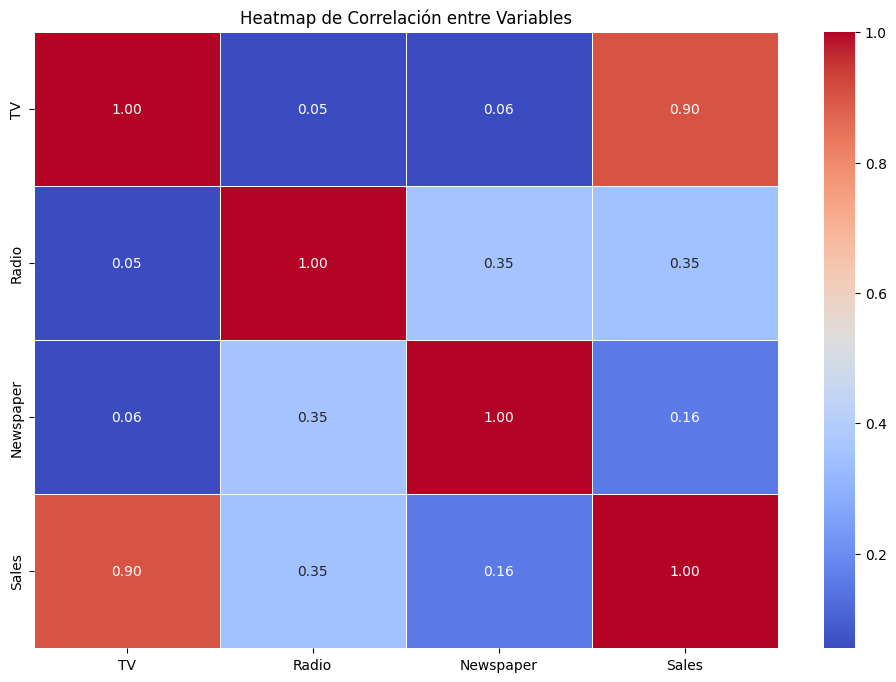

In [5]:
# Matriz de correlación
correlation_matrix = df.corr()
print("Matriz de correlación:")
print(correlation_matrix)

plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', cbar=True, linewidths=0.5)
plt.title("Heatmap de Correlación entre Variables")
plt.show()


## ¿Qué variables están más correlacionadas con Sales? ¿Hay correlación alta entre predictores?
1. Encontramos que la variable con la correlación más alta con `Sales` es `TV` con un valor de 0.90.
2. Correlación entre predictores `Radio` - `Newspaper`: con un valor de 0.35, para el resto de relaciones apenas alcanzamos un 0.06.


## Parte 3. Multicolinealidad
1. Calcula el VIF (Variance Inflation Factor) para cada predictor.
2. Crea un diagrama de barras  para mostrar el  VIF
3. Interpreta si hay multicolinealidad:
- ¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?
- ¿Qué implicaciones tiene esto para el modelo?


### Análisis de Multicolinealidad ###
    Variable       VIF
0      const  1.000000
1         TV  1.004611
2      Radio  1.144952
3  Newspaper  1.145187


/tmp/ipykernel_870/3635321713.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='VIF', y='Variable', data=vif_data, palette='coolwarm')


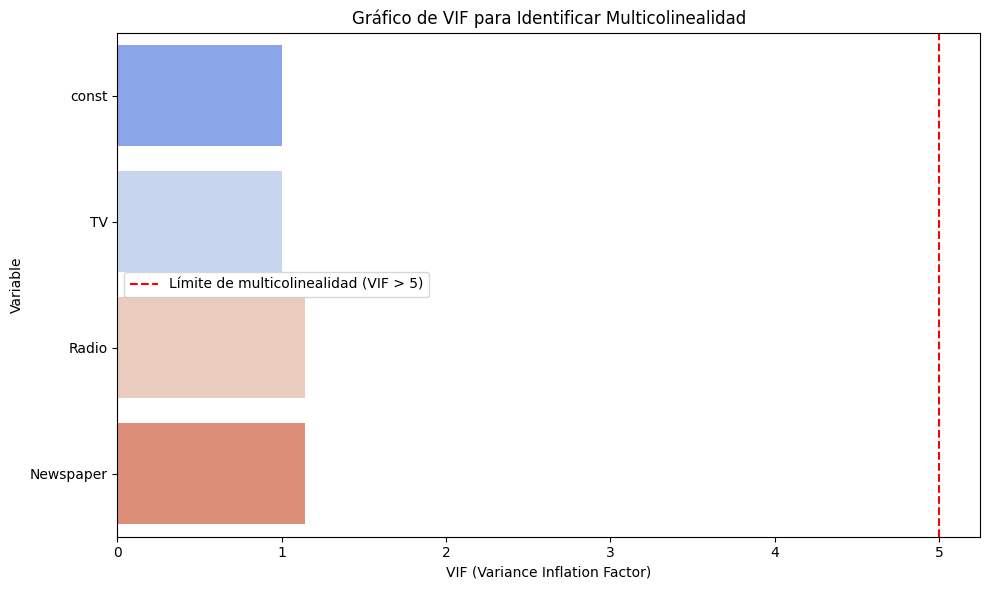

In [6]:
#1. Calcular el VIF para cada predictor.
X = add_constant(df.drop(columns=['Sales']))  # Matriz de características sin la variable dependiente
vif_data = pd.DataFrame()
vif_data['Variable'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

print("\n### Análisis de Multicolinealidad ###")
print(vif_data)

#Diagrama de barras
plt.figure(figsize=(10, 6))
sns.barplot(x='VIF', y='Variable', data=vif_data, palette='coolwarm')
plt.axvline(x=5, color='red', linestyle='--', label='Límite de multicolinealidad (VIF > 5)')
plt.xlabel('VIF (Variance Inflation Factor)')
plt.title('Gráfico de VIF para Identificar Multicolinealidad')
plt.legend()
plt.tight_layout()
plt.show()

## Interpretación
Encontramos un valor excelente de VIF para cada variable, donde apenas alcanzamos un máximo de 1.14, lo que indican valores saludables. Cada coeficiente del modelo mide el efecto de su variable de forma independiente

## Parte 4: Construcción del Modelo (Todas las variables Independientes), Evaluación

### 4.1 Entrenamiento del Modelo (Todas las Variables Independientes)

1. Entrena un modelo de regresión lineal múltiple usando TV, Radio y Newspaper como variables independientes.
2. Imprime el intercepto y los coeficientes del modelo.
3. Interpreta cada uno:
¿Qué significa cada uno de los coeficientes  en términos de ventas?

In [7]:
#Definir variables dependientes e independientes
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

In [8]:
#ntrenamiento del Modelo (Todas las Variables Independientes)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
model = LinearRegression()
model.fit(X_scaled,y)

LinearRegression()

In [9]:
coefficients = model.coef_
intercept = model.intercept_

print(f"\nCoeficientes estimados: {coefficients}")
print(f"Término independiente estimado: {intercept}")
#######################################################
print('\n')
equation = f"PRICE = {intercept} "
for i, coef in enumerate(coefficients):
  equation += f"+ ({coef} * {X.columns[i]}) "

equation #se obtiene el modelo con los coeficientes



Coeficientes estimados: [4.66270025 1.58465027 0.00729187]
Término independiente estimado: 15.130500000000001




'PRICE = 15.130500000000001 + (4.662700245086694 * TV) + (1.5846502733236385 * Radio) + (0.0072918683037688226 * Newspaper) '

## Interpretación

El modelo estimado es:

\[Sales = 15.13 + 4.66(TV) + 1.58(Radio) + 0.007(Newspaper)\]

#### Término independiente (15.13)
Representa las ventas estimadas cuando las variables independientes se encuentran en su valor de referencia.

#### Coeficiente de TV (4.66)
Un incremento de una desviación estándar en la inversión en TV aumenta las ventas en aproximadamente **4.66 unidades**, manteniendo constantes las demás variables.

#### Coeficiente de Radio (1.58)
Un incremento de una desviación estándar en la inversión en Radio aumenta las ventas en aproximadamente **1.58 unidades**, manteniendo constantes las demás variables.

#### Coeficiente de Newspaper (0.007)
Su efecto sobre las ventas es prácticamente nulo, ya que su coeficiente es muy cercano a cero.

### Conclusión
- **TV** es la variable que más influye en las ventas.
- **Radio** tiene una influencia positiva moderada.
- **Newspaper** aporta muy poca información al modelo.

### 4.2 Normalidad de los residuos

1. Calcula los residuos: residuos = y - y_pred.

2. Grafica un histograma con KDE de los residuos.

3. ¿Los residuos parecen distribuirse normalmente?

<Axes: xlabel='Sales', ylabel='Count'>

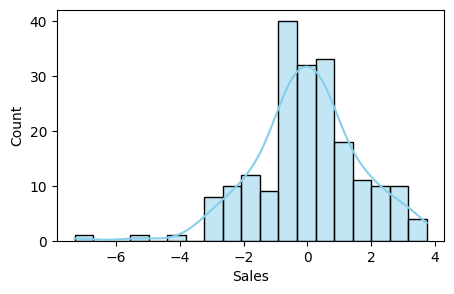

In [10]:
#Normalidad de los residuos
y_pred = model.predict(X_scaled)
residuals = y - y_pred

plt.figure(figsize=(5, 3))
sns.histplot(residuals, kde=True, color='skyblue', label='Residuos')

## Interpretación
Los residuos se calcularon como la diferencia entre los valores reales y los valores predichos por el modelo.

Al analizar el histograma y la curva KDE, se observa que los residuos presentan una distribución aproximadamente normal y centrada alrededor de cero. Aunque existen algunos valores extremos en la cola izquierda, la forma general de la distribución es similar a una campana.

### 4.3. Homocedasticidad

1. Grafica los residuos contra los valores predichos.
2. ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?

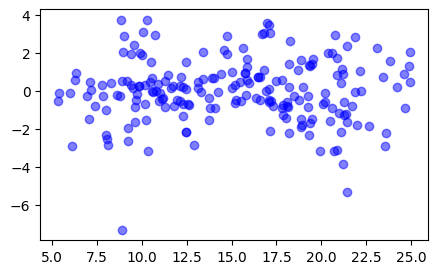

In [11]:
# Homocedasticidad
plt.figure(figsize=(5, 3))
plt.scatter(y_pred, residuals, color='blue', alpha=0.5)

## Interpretación
El gráfico de residuos frente a valores predichos no muestra patrones evidentes ni formas de embudo. Los residuos parecen dispersarse aleatoriamente alrededor de cero y con una variabilidad relativamente constante. El supuesto de homocedasticidad parece cumplirse.

### 4.4 Q-Q Plot

1. Graficar el Q-Q Plot
2. Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.

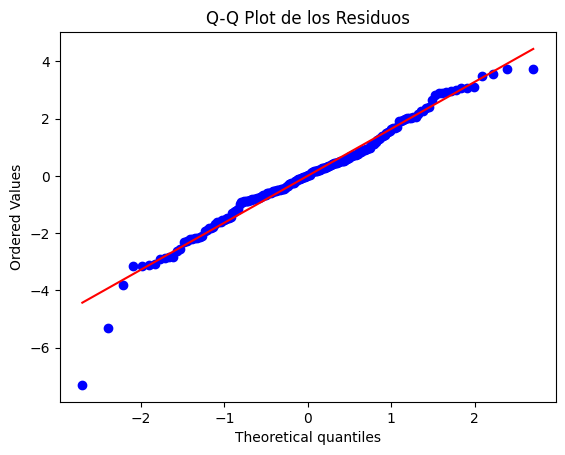

In [12]:
#Q-Q Plot
import scipy.stats as stats
stats.probplot(residuals, dist='norm', plot=plt)
plt.title('Q-Q Plot de los Residuos')
plt.show()

## Interpretación

El gráfico Q-Q muestra que la mayoría de los puntos se encuentran cerca de la línea diagonal de referencia, lo que indica que los residuos siguen aproximadamente una distribución normal.

Se observan pequeñas desviaciones en los extremos, especialmente en la cola izquierda, lo que sugiere la presencia de algunos valores atípicos. Sin embargo, estas desviaciones no son suficientemente grandes como para invalidar el supuesto de normalidad.

### 4.5. Evaluación del Modelo

1. Calcula las métricas: a) MSE (error cuadrático medio), b) RMSE (raíz del error cuadrático medio), c) R² (coeficiente de determinación)

2. ¿Qué nos dicen estas métricas sobre el ajuste del modelo?


In [13]:
#Evaluación del Modelo
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y, y_pred)

print(f"Error Cuadrático Medio (MSE): {mse}")
print(f"Raíz del Error Cuadrático Medio (RMSE): {rmse}")
print(f"Coeficiente de Determinación (R²): {r2}")

Error Cuadrático Medio (MSE): 2.7060061476273165
Raíz del Error Cuadrático Medio (RMSE): 1.6449942697855566
Coeficiente de Determinación (R²): 0.9025912899684558


## 4.5 Evaluación del Modelo

- **MSE = 2.7060:** El error cuadrático medio es bajo, indicando que las predicciones están cerca de los valores reales.
- **RMSE = 1.6450:** En promedio, las predicciones difieren de los valores reales en aproximadamente 1.65 unidades de venta.
- **R² = 0.9026:** El modelo explica aproximadamente el 90.26% de la variabilidad de las ventas.

**Conclusión:** El modelo presenta un excelente ajuste y una alta capacidad explicativa de los datos.

### 4.6. Visualización de Predicciones

1. Crea un gráfico comparando Sales reales vs Sales predichas.

2. Puedes usar plt.scatter(y_true, y_pred) para evaluar visualmente el ajuste.
3.¿Qué observas?¿Qué observas? ¿Qué información puedes obtener de esta gráfica?

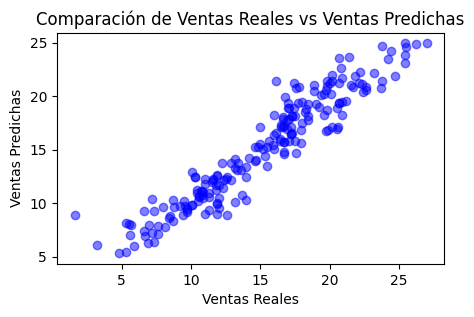

In [14]:
#Visualización de las Predicciones
plt.figure(figsize=(5, 3))
plt.scatter(y, y_pred, color='blue', alpha=0.5)
plt.xlabel('Ventas Reales')
plt.ylabel('Ventas Predichas')
plt.title('Comparación de Ventas Reales vs Ventas Predichas')
plt.show()

### 4.6 Visualización de Predicciones

En el gráfico de ventas reales frente a ventas predichas, los puntos se distribuyen cerca de una línea recta ascendente, lo que indica que las predicciones del modelo son muy similares a los valores reales.

Se observa una fuerte relación lineal entre ambas variables y una dispersión relativamente pequeña de los puntos.

**Conclusión:** El modelo presenta un buen ajuste y una alta capacidad para predecir las ventas, lo que coincide con el valor obtenido de \(R^2 = 0.903\).

### 4.7 Verificar el impacto de los atributos en el modelo

1. Ajusta el modelo usando statsmodels en lugar de scikit-learn para obtener los valores p.
2. Interpreta los resultados:

 - Observa los valores P>|t| en la tabla de salida.

 - ¿Qué variables tienen p-value menores a 0.05?

 - ¿Cuál es la conclusión sobre esas variables?


In [15]:
#P-values
import statsmodels.api as sm

X = sm.add_constant(X)
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                     605.4
Date:                Sat, 31 Oct 2026   Prob (F-statistic):           8.13e-99
Time:                        01:40:06   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             774.7
Df Residuals:                     196   BIC:                             787.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6251      0.308     15.041      0.0

##Interpretación

- **TV** tiene un p-value menor que 0.05, por lo que influye significativamente en las ventas.
- **Radio** también presenta un p-value menor que 0.05, indicando una relación significativa con las ventas.
- **Newspaper** tiene un p-value muy superior a 0.05, por lo que no existe evidencia estadística suficiente para afirmar que afecta las ventas.

**Conclusión:** Las variables **TV** y **Radio** son predictores significativos de las ventas, mientras que **Newspaper** no aporta información relevante al modelo.

##Parte 5:  Construcción del Modelo (sin Multicolinealidad), Evaluación

En el caso de que hayas detectado variables con multicolinealidad. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

In [16]:
#Se omite esta sección ya que no hay variables con multicolinealidad a eliminar

## Parte 6: Construcción del Modelo (sin variables que no muestran una relación lineal), Evaluación

En el caso de que hayas detectado variables sin una relación lineal con la variable dependiente. Elimina aquellas que presenten esta característica y realiza lo siguiente.

En el caso de que hayas detectado variables sin una relación lineal. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

*La variable Newspaper fue eliminada del modelo debido a que presentó un p-value de 0.954, superior al nivel de significancia de 0.05. Esto indica que no existe evidencia estadística suficiente para afirmar que tiene un efecto significativo sobre las ventas.*

*Por lo tanto, se construyó un nuevo modelo utilizando únicamente las variables TV y Radio, que sí mostraron una relación significativa con la variable dependiente.*

In [17]:
x2 = df[['TV', 'Radio']]
y2 = df['Sales']

In [18]:
#ntrenamiento del Modelo (Todas las Variables Independientes)
scaler2 = StandardScaler()
X_scaled2 = scaler.fit_transform(x2)
model2 = LinearRegression()
model2.fit(X_scaled2,y2)

LinearRegression()

In [19]:
coefficients2 = model2.coef_
intercept2 = model2.intercept_

print(f"\nCoeficientes estimados: {coefficients2}")
print(f"Término independiente estimado: {intercept2}")
#######################################################
print('\n')
equation = f"PRICE = {intercept2} "
for i, coef in enumerate(coefficients2):
  equation += f"+ ({coef} * {x2.columns[i]}) "

equation #se obtiene el modelo con los coeficientes



Coeficientes estimados: [4.66297261 1.58721742]
Término independiente estimado: 15.130500000000001




'PRICE = 15.130500000000001 + (4.662972611875511 * TV) + (1.5872174231801197 * Radio) '

In [20]:
#Evaluación del Modelo
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y2, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y2, y_pred)

print(f"Error Cuadrático Medio (MSE): {mse}")
print(f"Raíz del Error Cuadrático Medio (RMSE): {rmse}")
print(f"Coeficiente de Determinación (R²): {r2}")

Error Cuadrático Medio (MSE): 2.7060061476273165
Raíz del Error Cuadrático Medio (RMSE): 1.6449942697855566
Coeficiente de Determinación (R²): 0.9025912899684558


##7. Conclusiones.

¿Cuál de los tres modelos construidos fue el mejor?
¿Cuál fue el atributo que mas influencia tiene en las ventas?

## Conclusiones

Se construyeron dos modelos de regresión para explicar las ventas a partir de la inversión en publicidad.

El mejor modelo fue el que utilizó únicamente las variables **TV** y **Radio**, ya que mantuvo prácticamente el mismo poder predictivo que el modelo completo (R² ≈ 0.903) y eliminó la variable **Newspaper**, que no resultó estadísticamente significativa (p-value = 0.954).

Respecto a la importancia de las variables, **TV fue el atributo con mayor influencia sobre las ventas**, ya que presentó el coeficiente más alto (4.66 en el modelo estandarizado). La variable **Radio** también mostró una influencia positiva importante, mientras que **Newspaper** tuvo un efecto prácticamente nulo.

Por lo tanto, la inversión en publicidad televisiva es el factor que más contribuye al incremento de las ventas, seguida por la publicidad en radio.